# PayWatch: feature engineering and leakage checks

The causal pipeline in `src/features/` turns raw IEEE-CIS rows into model features. This notebook runs it on the real data and then tries to break it: time-ordered splits, train-only encodings and an independent recomputation of the lagged fraud-history features. Only aggregates are shown, never raw rows.

In [1]:
import glob, json, os, re, shutil, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve, precision_recall_curve
warnings.filterwarnings("ignore")
%matplotlib inline
pd.set_option("display.width", 140)
T0 = time.time()
DEVICE = "cuda" if shutil.which("nvidia-smi") else "cpu"
find = lambda p: sorted(glob.glob(p, recursive=True))
sys.path.insert(0, os.path.dirname(find("/kaggle/input/**/upi_fingerprint.py")[0]))
sys.path.insert(0, os.path.dirname(find("/kaggle/input/**/evasion.py")[0]))
import engineer
from entity_history import BASE_KEYS
RAW = os.path.dirname(find("/kaggle/input/**/train_transaction.csv")[0])
SPEC = json.load(open(find("/kaggle/input/**/prod_compact/serving_spec.json")[0]))
COLS = SPEC["features"]
SHIPPED = find("/kaggle/input/**/prod_compact/xgb_seed*.json")
raw = engineer.load_raw(RAW)
base = engineer.build_base(raw.copy(), lags=(7,), decay_lags=(), velocity=False, key_names=BASE_KEYS)
(tr, va, te), art = engineer.finalize(base, d_mode="anchor", return_artifacts=True)
(X_tr, y_tr, t_tr), (X_va, y_va, t_va), (X_te, y_te, t_te) = tr, va, te
UPI_B = {"amount_vs_7day_avg_ratio", "merchant_category_entropy", "hour_deviation_from_user_mean",
         "days_since_last_large_txn", "is_new_merchant", "is_p2p"}


def family(f):
    if f.startswith("h7_"):
        return "entity fraud history"
    if f.startswith("uid_") or f in UPI_B:
        return "UPI behaviour"
    if f.endswith("_freq"):
        return "frequency encoding"
    if re.fullmatch(r"D\d+", f):
        return "time deltas (D)"
    if re.fullmatch(r"V\d+", f):
        return "Vesta V"
    if f.startswith("id_") or f.startswith("Device"):
        return "identity / device"
    if re.fullmatch(r"[CM]\d+", f):
        return "counts / match flags (C, M)"
    return "raw transaction"


def recall_at_fpr(y, p, f):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.interp(f, fpr, tpr))


def op_threshold(score, y, target, n_min=100):
    order = np.argsort(-score)
    tp = np.cumsum(y[order])
    n = np.arange(1, len(y) + 1)
    ok = np.where((tp / n >= target) & (n >= n_min))[0]
    return float(score[order][ok.max()]) if len(ok) else None


def shipped_boosters():
    out = []
    for p in SHIPPED:
        b = xgb.Booster()
        b.load_model(p)
        out.append(b)
    return out


def ensemble_score(boosters, X):
    d = xgb.DMatrix(pd.DataFrame(np.asarray(X, dtype=np.float32), columns=COLS))
    return np.mean([b.predict(d) for b in boosters], axis=0)


print(f"device: {DEVICE} | pipeline built in {(time.time() - T0) / 60:.1f} min | train {X_tr.shape}, val {X_va.shape}, test {X_te.shape} | compact features: {len(COLS)}")

device: cpu | pipeline built in 1.1 min | train (413378, 452), val (88581, 452), test (88581, 452) | compact features: 120


## 1. What the pipeline produces

,features,in_compact
family,,
Vesta V,338,39
identity / device,30,11
"counts / match flags (C, M)",23,16
entity fraud history,15,15
time deltas (D),14,11
raw transaction,13,11
UPI behaviour,12,10
frequency encoding,7,7


raw columns: 434 -> kept 452 model features (full) -> 120 (compact, chosen by SHAP rank on validation)


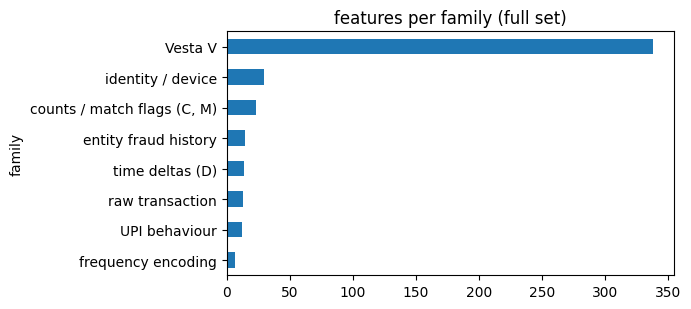

In [2]:
all_cols = art["feature_columns"]
fam = pd.DataFrame({"feature": all_cols, "family": [family(c) for c in all_cols]})
fam["in_compact_model"] = fam.feature.isin(COLS)
summary = fam.groupby("family").agg(features=("feature", "size"), in_compact=("in_compact_model", "sum")).sort_values("features", ascending=False)
display(summary)
print(f"raw columns: {raw.shape[1]} -> kept {len(all_cols)} model features (full) -> {len(COLS)} (compact, chosen by SHAP rank on validation)")
summary.features.plot(kind="barh", figsize=(7, 3.2), title="features per family (full set)"); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

## 2. Split: strictly time-ordered 70 / 15 / 15

A random split would let the model see the future of a card. Rows are sorted by `TransactionDT` and cut by position.

In [3]:
spl = pd.DataFrame({"rows": [len(y_tr), len(y_va), len(y_te)], "fraud_rate": [y_tr.mean(), y_va.mean(), y_te.mean()],
                    "start_day": [t_tr.min() / 86400, t_va.min() / 86400, t_te.min() / 86400],
                    "end_day": [t_tr.max() / 86400, t_va.max() / 86400, t_te.max() / 86400]}, index=["train", "validation", "test"])
display(spl.round(4))
assert t_tr.max() <= t_va.min() and t_va.max() <= t_te.min(), "splits overlap in time"
print("check passed: every validation row is later than every train row, every test row later than every validation row")

,rows,fraud_rate,start_day,end_day
train,413378,0.0352,1.0000,120.8101
validation,88581,0.0343,120.8102,152.2204
test,88581,0.0348,152.2208,182.9992


check passed: every validation row is later than every train row, every test row later than every validation row


## 3. Encodings fitted on train only

Frequency encodings use train counts. Values never seen in train get frequency 0 on val/test instead of leaking their own counts.

In [4]:
rows = []
for col in art["freq_tables"]:
    for name, key in (("validation", X_va), ("test", X_te)):
        zero = float((key[f"{col}_freq"] == 0).mean())
        rows.append({"column": col, "split": name, "share_with_frequency_0": round(zero, 4)})
display(pd.DataFrame(rows).pivot(index="column", columns="split", values="share_with_frequency_0"))
print("train frequency tables sum to 1 per column:", {c: round(sum(t.values()), 6) for c, t in list(art["freq_tables"].items())[:4]})

split,test,validation
column,,
P_emaildomain,0.1810,0.1595
R_emaildomain,0.7909,0.8224
addr1,0.1049,0.1007
card1,0.0137,0.0109
card2,0.0182,0.0090
card3,0.0085,0.0001
card5,0.0116,0.0033


train frequency tables sum to 1 per column: {'card1': 1.0, 'card2': 1.0, 'card3': 1.0, 'card5': 1.0}


## 4. Lagged fraud history: independent recomputation

For a row at time t the history features may only use rows with `TransactionDT <= t - 7 days` (the label has had time to arrive) and never the row's own label. Below, 400 random rows are recomputed from scratch with plain pandas and compared with the pipeline's `h7_card_n` and `h7_card_fraud_n`.

In [5]:
from upi_fingerprint import make_card_key
b = base.sort_values("TransactionDT").reset_index(drop=True)
b["card_key"] = make_card_key(b)
rng = np.random.default_rng(0)
cand = np.where(b["h7_card_n"].to_numpy() > 0)[0]
pick = rng.choice(cand, 400, replace=False)
groups = {k: (g["TransactionDT"].to_numpy(), g["isFraud"].to_numpy()) for k, g in b[b.card_key.isin(set(b.card_key.iloc[pick]))].groupby("card_key")}
bad_n = bad_f = 0
for i in pick:
    ts, lab = groups[b.card_key.iloc[i]]
    m = ts <= b.TransactionDT.iloc[i] - 7 * 86400
    bad_n += int(m.sum() != b.h7_card_n.iloc[i])
    bad_f += int(lab[m].sum() != b.h7_card_fraud_n.iloc[i])
print(f"mismatches vs independent recomputation: count {bad_n}/400, fraud count {bad_f}/400")
assert bad_n == 0 and bad_f == 0
print("pipeline and recomputation agree; a row's own label and the last 7 days of labels are never used")

mismatches vs independent recomputation: count 0/400, fraud count 0/400
pipeline and recomputation agree; a row's own label and the last 7 days of labels are never used


## 5. How informative is each feature on its own? (validation ROC-AUC, no model)

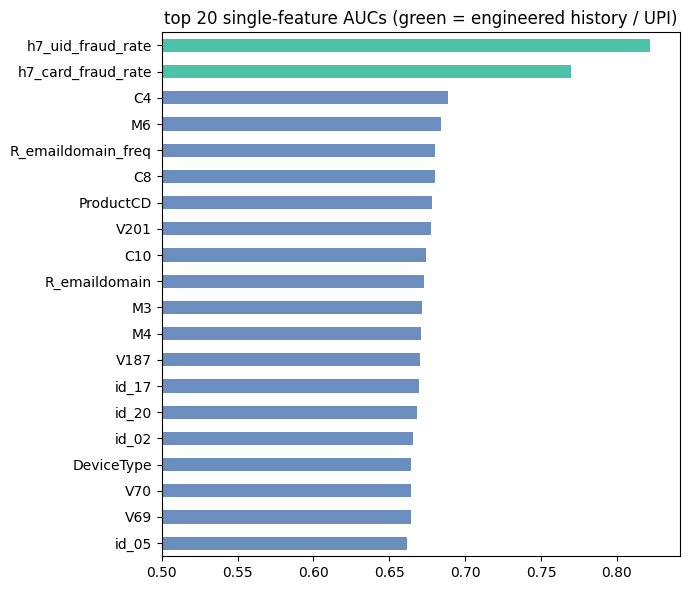

                             count    max   mean
family                                          
UPI behaviour                   10  0.580  0.522
Vesta V                         39  0.677  0.590
counts / match flags (C, M)     16  0.689  0.630
entity fraud history            15  0.822  0.620
frequency encoding               7  0.680  0.588
identity / device               11  0.669  0.645
raw transaction                 11  0.678  0.574
time deltas (D)                 11  0.644  0.579


In [6]:
auc = {}
for c in COLS:
    v = X_va[c].to_numpy()
    if np.nanstd(v) > 0:
        a = roc_auc_score(y_va, v)
        auc[c] = max(a, 1 - a)
s = pd.Series(auc).sort_values(ascending=False)
top = s.head(20)
colors = ["#4cc2a6" if family(f) in ("entity fraud history", "UPI behaviour") else "#6c8ebf" for f in top.index]
top[::-1].plot(kind="barh", figsize=(7, 6), color=colors[::-1], title="top 20 single-feature AUCs (green = engineered history / UPI)")
plt.xlim(0.5, top.max() + 0.02); plt.tight_layout(); plt.show()
print(pd.DataFrame({"family": [family(f) for f in s.index], "auc": s.values}).groupby("family").auc.agg(["count", "max", "mean"]).round(3))

## Takeaways

- Splits are time-ordered and the encodings are train-only; the label-lag logic reproduces exactly under an independent recomputation.
- Engineered entity-history and behaviour features carry real single-feature signal, but no feature alone is close to the final model: the gain is in combining them.
- The user id is a reconstructed proxy (card fields + address + account-age anchor), not a real UPI id.